In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay, average_precision_score)
from xgboost import XGBClassifier


# Explore and EDA

-- columns description 
type - CASH-IN, CASH-OUT, DEBIT, PAYMENT and TRANSFER.

amount -
amount of the transaction in local currency.

nameOrig - customer who started the transaction

oldbalanceOrg - initial balance before the transaction

newbalanceOrig - new balance after the transaction.

nameDest - customer who is the recipient of the transaction

oldbalanceDest - initial balance recipient before the transaction. Note that there is not information for customers that start with M (Merchants).

newbalanceDest - new balance recipient after the transaction. Note that there is not information for customers that start with M (Merchants).

isFraud - This is the transactions made by the fraudulent agents inside the simulation. In this specific dataset the fraudulent behavior of the agents aims to profit by taking control or customers accounts and try to empty the funds by transferring to another account and then cashing out of the system.

isFlaggedFraud - The business model aims to control massive transfers from one account to another and flags illegal attempts. An illegal attempt in this dataset is an attempt to transfer more than 200.000 in a single transaction.

In [2]:
data=pd.read_csv("/media/yillzahar/863270C13270B82F/Real-Time-Transaction-Fraud-Detection/data/fraud_data.csv")
data.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [3]:
data.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [4]:
data.duplicated().sum()

np.int64(0)

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [6]:
data.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [7]:
data['isFraud'].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [8]:
data2=data[["nameOrig","nameDest","oldbalanceOrg","newbalanceOrig","oldbalanceDest","newbalanceDest","isFraud"]]
fraud = data2[data2["isFraud"] == 1].groupby("nameOrig")
fraud.head(50)


,nameOrig,nameDest,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
2,C1305486145,C553264065,181.00,0.0,0.00,0.00,1
3,C840083671,C38997010,181.00,0.0,21182.00,0.00,1
251,C1420196421,C972765878,2806.00,0.0,0.00,0.00,1
252,C2101527076,C1007251739,2806.00,0.0,26202.00,0.00,1
680,C137533655,C1848415041,20128.00,0.0,0.00,0.00,1
...,...,...,...,...,...,...,...
6362615,C786484425,C776919290,339682.13,0.0,0.00,339682.13,1
6362616,C1529008245,C1881841831,6311409.28,0.0,0.00,0.00,1
6362617,C1162922333,C1365125890,6311409.28,0.0,68488.84,6379898.11,1
6362618,C1685995037,C2080388513,850002.52,0.0,0.00,0.00,1


In [9]:
data3=data[["nameOrig","oldbalanceOrg","newbalanceOrig","oldbalanceDest","newbalanceDest","isFraud"]]
fraud0= data3[data3["isFraud"] == 0].groupby("nameOrig")
fraud0.head(50)


,nameOrig,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
0,C1231006815,170136.0,160296.36,0.00,0.00,0
1,C1666544295,21249.0,19384.72,0.00,0.00,0
4,C2048537720,41554.0,29885.86,0.00,0.00,0
5,C90045638,53860.0,46042.29,0.00,0.00,0
6,C154988899,183195.0,176087.23,0.00,0.00,0
...,...,...,...,...,...,...
6362319,C642813806,518802.0,510167.71,0.00,0.00,0
6362320,C691808084,3859.0,0.00,0.00,159188.22,0
6362321,C102120699,168046.0,0.00,24893.67,211167.51,0
6362322,C614459560,13492.0,0.00,0.00,82096.45,0


amount            0.076688
type_TRANSFER     0.053869
isFlaggedFraud    0.044109
step              0.031578
type_CASH_OUT     0.011256
oldbalanceOrg     0.010154
newbalanceDest    0.000535
type_DEBIT       -0.002911
oldbalanceDest   -0.005885
newbalanceOrig   -0.008148
type_CASH_IN     -0.019089
type_PAYMENT     -0.025697
Name: isFraud, dtype: float64


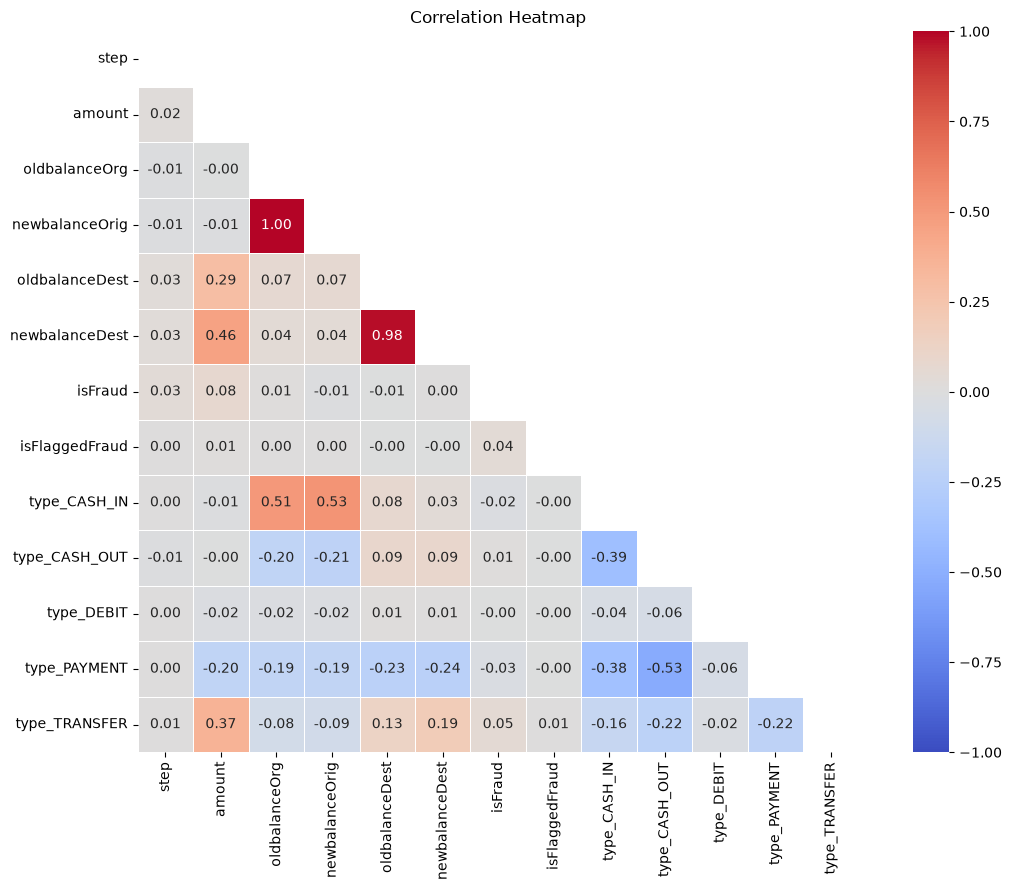

In [10]:


corr_df = data.drop(columns=["nameOrig", "nameDest"])
corr_df = pd.get_dummies(corr_df, columns=["type"], dtype=int)

corr = corr_df.corr()

print(corr["isFraud"].drop("isFraud").sort_values(ascending=False))

mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(12, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, linewidths=0.5, square=True)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


In [11]:


def get_numeric_cols(df, exclude=("isFraud", "isFlaggedFraud", "step")):
    """Numeric columns, minus target/flag columns."""
    return [c for c in df.select_dtypes(include="number").columns if c not in exclude]


def plot_distributions(df, cols=None, log=False, bins=50, sample=200_000, ncols=3):
    """Histogram + KDE for each column. log=True applies log1p to handle skew."""
    cols = cols or get_numeric_cols(df)
    d = df[cols].sample(min(sample, len(df)), random_state=42)  # sample for speed
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows))
    axes = np.array(axes).ravel()
    for ax, col in zip(axes, cols):
        x = np.log1p(d[col].clip(lower=0)) if log else d[col]
        sns.histplot(x, bins=bins, kde=True, ax=ax)
        ax.set_title(f"{'log1p(' + col + ')' if log else col}  |  skew={df[col].skew():.2f}")
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()


def plot_boxplots(df, cols=None, log=False, by=None, sample=200_000, ncols=3):
    """Boxplot per column to see outliers. by='isFraud' splits by class."""
    cols = cols or get_numeric_cols(df)
    d = df.sample(min(sample, len(df)), random_state=42)
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows))
    axes = np.array(axes).ravel()
    for ax, col in zip(axes, cols):
        y = np.log1p(d[col].clip(lower=0)) if log else d[col]
        sns.boxplot(x=d[by] if by else None, y=y, ax=ax, flierprops={"markersize": 2})
        ax.set_title(f"{'log1p(' + col + ')' if log else col}")
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()


def outlier_summary(df, cols=None, k=1.5):
    """Count outliers per column using the IQR rule (outside Q1 - k*IQR, Q3 + k*IQR)."""
    cols = cols or get_numeric_cols(df)
    rows = []
    for col in cols:
        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        low, high = q1 - k * iqr, q3 + k * iqr
        mask = (df[col] < low) | (df[col] > high)
        row = {"column": col, "skew": df[col].skew(), "lower": low, "upper": high,
               "n_outliers": mask.sum(), "pct_outliers": 100 * mask.mean()}
        if "isFraud" in df:
            row["fraud_rate_in_outliers_%"] = 100 * df.loc[mask, "isFraud"].mean() if mask.any() else 0
        rows.append(row)
    return pd.DataFrame(rows).sort_values("pct_outliers", ascending=False).round(3)


In [12]:
get_numeric_cols(data)

['amount',
 'oldbalanceOrg',
 'newbalanceOrig',
 'oldbalanceDest',
 'newbalanceDest']

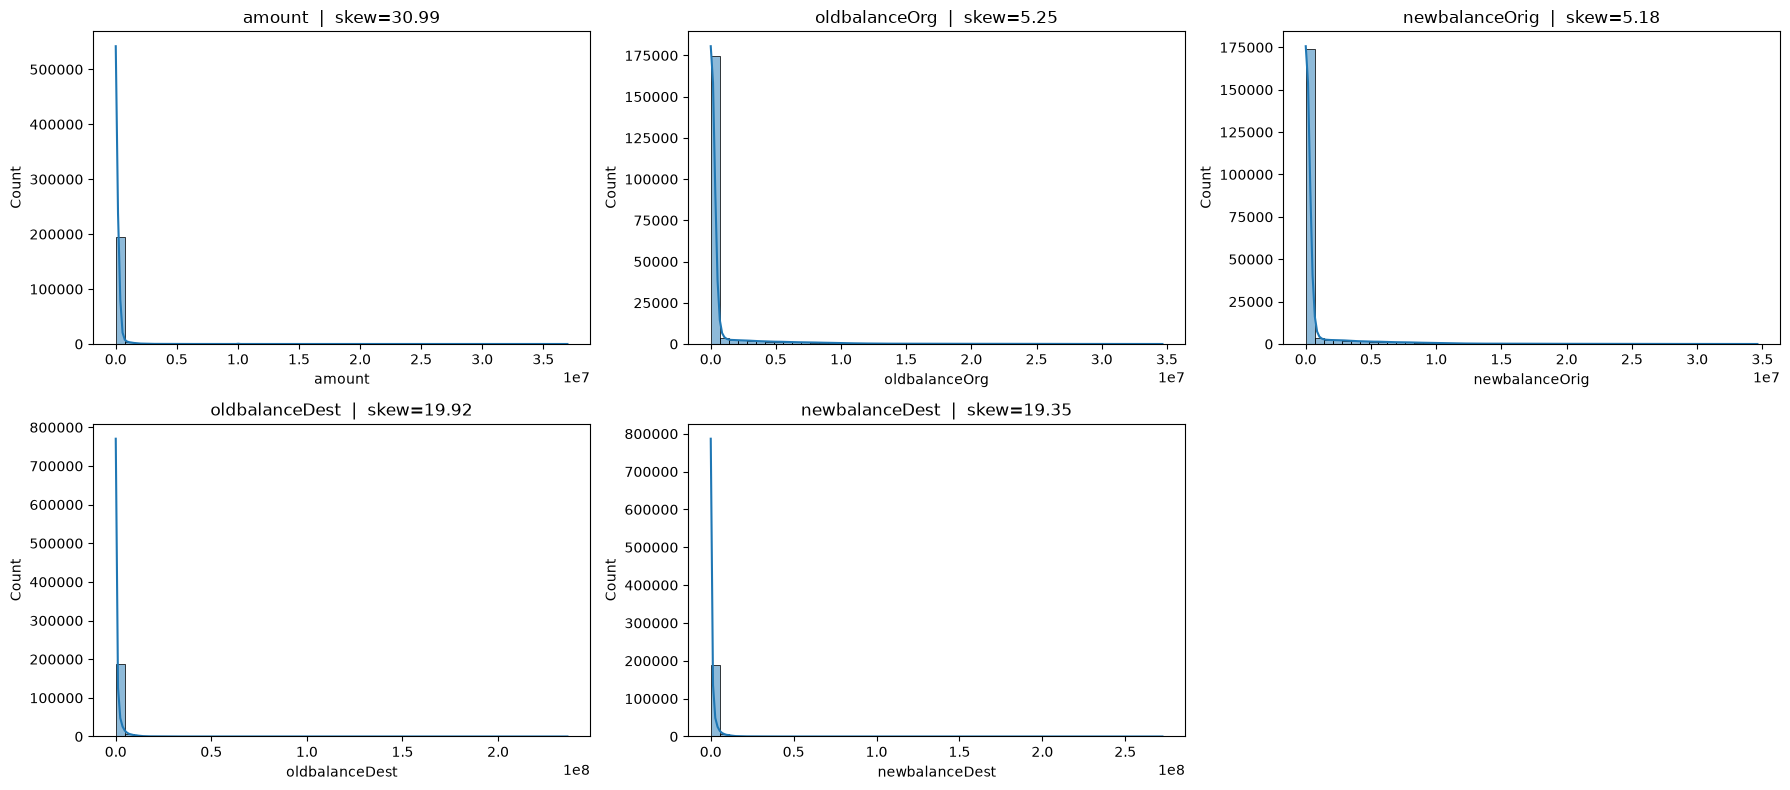

In [13]:
plot_distributions(data)

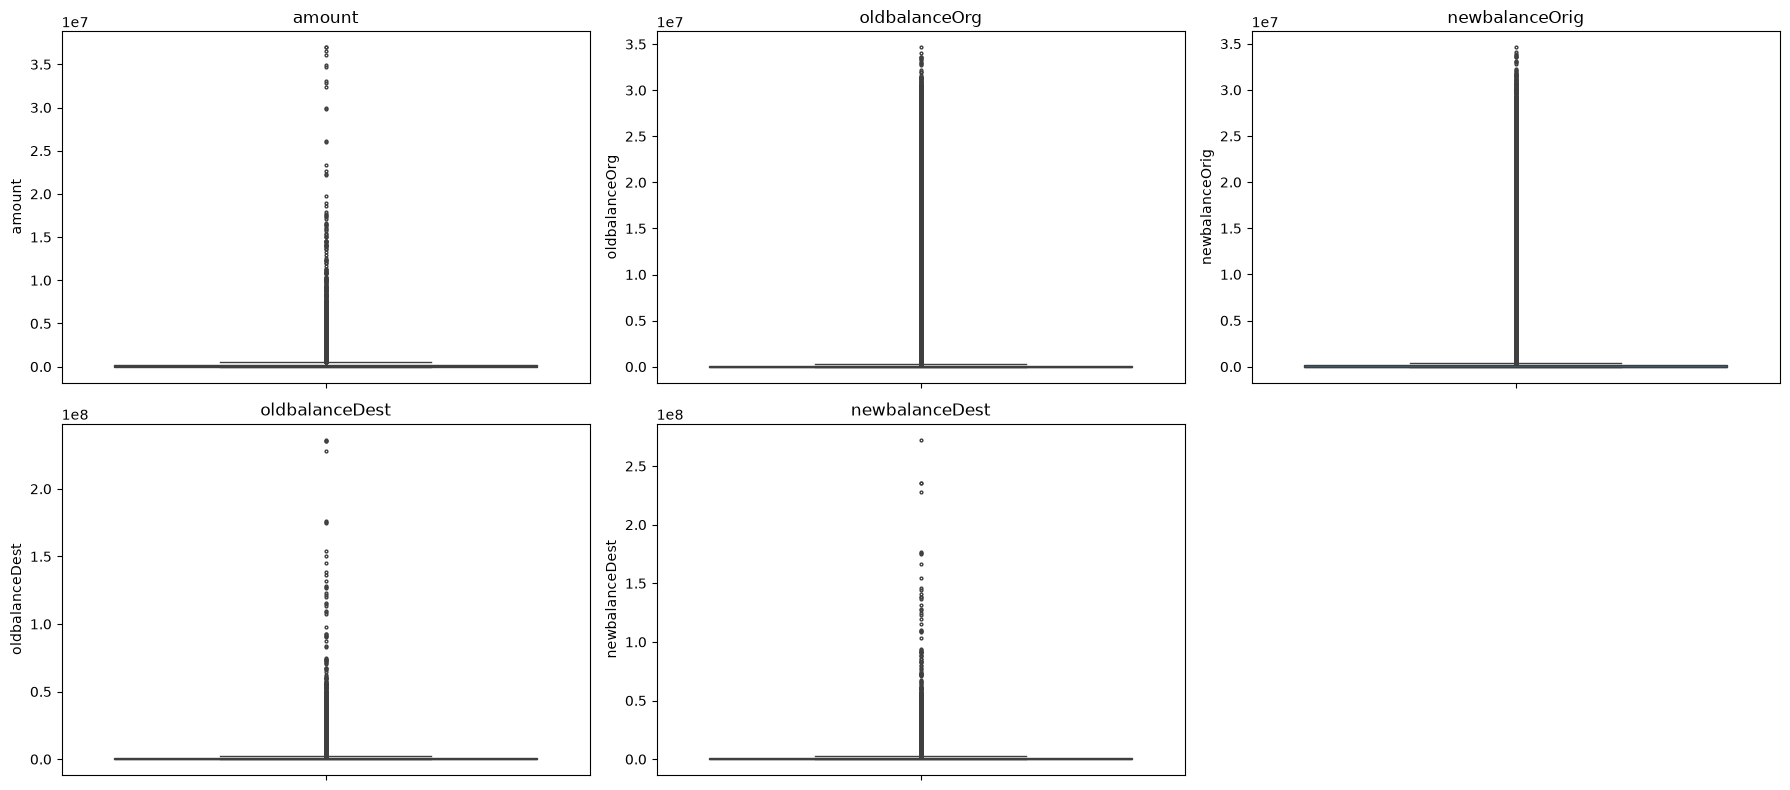

In [14]:
plot_boxplots(data)

In [15]:
outlier_summary(data)

,column,skew,lower,upper,n_outliers,pct_outliers,fraud_rate_in_outliers_%
1,oldbalanceOrg,5.249,-160972.762,268287.938,1112507,17.485,0.446
2,newbalanceOrig,5.177,-216387.615,360646.025,1053391,16.556,0.015
3,oldbalanceDest,19.922,-1414555.061,2357591.769,786135,12.356,0.059
4,newbalanceDest,19.352,-1667863.875,2779773.125,738527,11.607,0.149
0,amount,30.994,-279608.291,501719.339,338078,5.314,1.140


In [16]:
features = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

display(data[features].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
).T)

print("Negative values:")
display((data[features] < 0).sum())

,count,mean,std,min,50%,75%,90%,95%,99%,99.9%,max
amount,6362620.0,1.798619e+05,6.038582e+05,0.0,74871.940,2.087215e+05,365423.309,5.186342e+05,1.615979e+06,8.956798e+06,9.244552e+07
oldbalanceOrg,6362620.0,8.338831e+05,2.888243e+06,0.0,14208.000,1.073152e+05,1822508.289,5.823702e+06,1.602726e+07,2.682593e+07,5.958504e+07
newbalanceOrig,6362620.0,8.551137e+05,2.924049e+06,0.0,0.000,1.442584e+05,1970344.793,5.980262e+06,1.617616e+07,2.697166e+07,4.958504e+07
oldbalanceDest,6362620.0,1.100702e+06,3.399180e+06,0.0,132705.665,9.430367e+05,2914266.669,5.147230e+06,1.237182e+07,3.439279e+07,3.560159e+08
newbalanceDest,6362620.0,1.224996e+06,3.674129e+06,0.0,214661.440,1.111909e+06,3194869.671,5.515716e+06,1.313787e+07,3.953157e+07,3.561793e+08


Negative values:


amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
dtype: int64

In [17]:

from scipy.stats import skew

features = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

comparison = []

for col in features:
    original = data[col]
    transformed = np.log1p(original)

    comparison.append({
        "feature": col,
        "original_skew": skew(original),
        "log1p_skew": skew(transformed),
        "original_median": original.median(),
        "log1p_median": transformed.median()
    })

display(pd.DataFrame(comparison).round(3))

,feature,original_skew,log1p_skew,original_median,log1p_median
0,amount,30.994,-0.555,74871.940,11.224
1,oldbalanceOrg,5.249,-0.260,14208.000,9.562
2,newbalanceOrig,5.177,0.440,0.000,0.000
3,oldbalanceDest,19.922,-0.213,132705.665,11.796
4,newbalanceDest,19.352,-0.387,214661.440,12.277


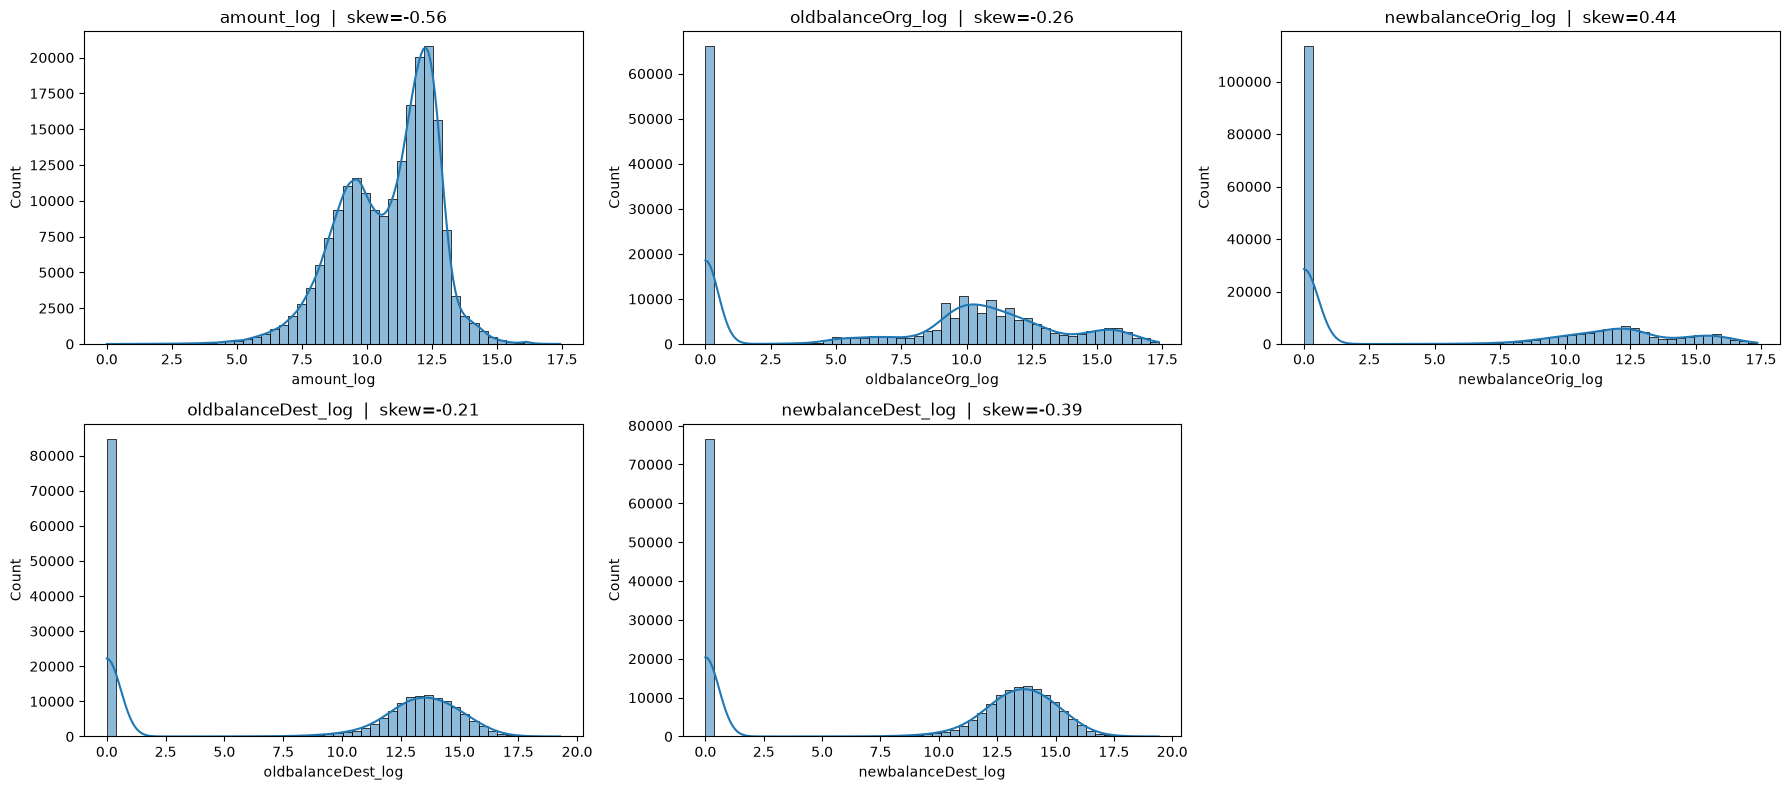

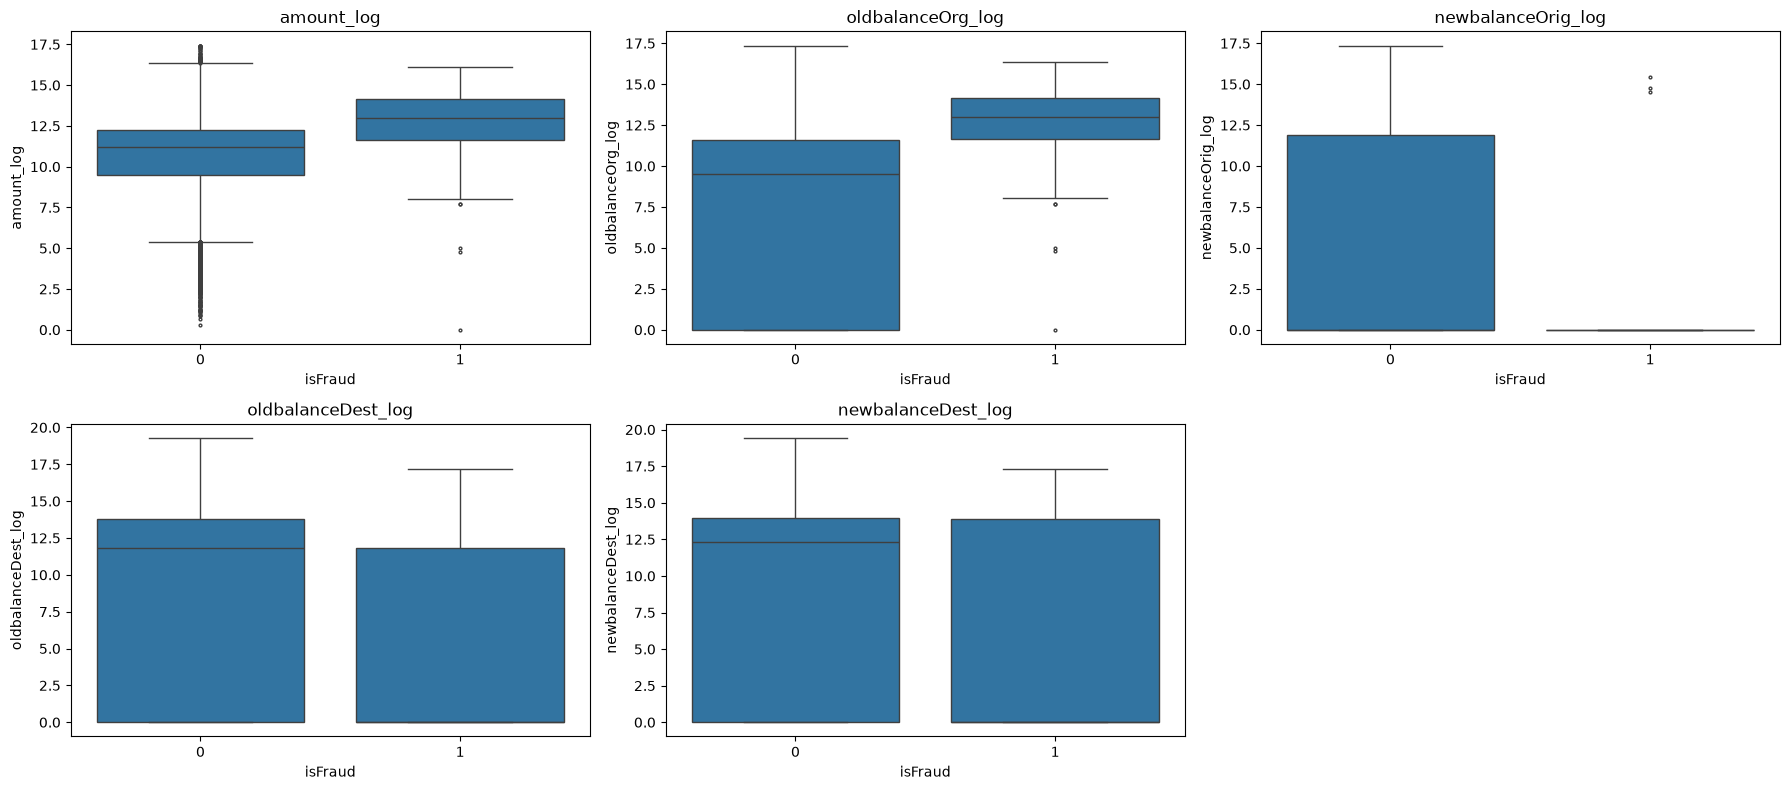

,column,skew,lower,upper,n_outliers,pct_outliers,fraud_rate_in_outliers_%
0,amount_log,-0.555,5.383,16.368,32429,0.51,0.111
1,oldbalanceOrg_log,-0.260,-17.375,28.959,0,0.00,0.000
2,newbalanceOrig_log,0.440,-17.819,29.698,0,0.00,0.000
3,oldbalanceDest_log,-0.213,-20.635,34.392,0,0.00,0.000
4,newbalanceDest_log,-0.387,-20.882,34.804,0,0.00,0.000


In [20]:
def make_log_version(df, cols=None, suffix="_log"):
    """Return a copy of df where each col is replaced by its log1p version (col + suffix)."""
    cols = cols or ["amount", "oldbalanceOrg", "newbalanceOrig",
                    "oldbalanceDest", "newbalanceDest"]
    out = df.copy()
    for col in cols:
        out[col + suffix] = np.log1p(out[col].clip(lower=0))
    return out.drop(columns=cols)

# Option 1: replace the columns in place (same names, log values)
data_log = make_log_version(data)

# Option 2: keep the originals and add amount_log, oldbalanceOrg_log, ...

data_log.head()

plot_distributions(data_log)
plot_boxplots(data_log, by="isFraud")
outlier_summary(data_log)


In [21]:
data_log.head()

,step,type,nameOrig,nameDest,isFraud,isFlaggedFraud,amount_log,oldbalanceOrg_log,newbalanceOrig_log,oldbalanceDest_log,newbalanceDest_log
0,1,PAYMENT,C1231006815,M1979787155,0,0,9.194276,12.044359,11.984786,0.000000,0.0
1,1,PAYMENT,C1666544295,M2044282225,0,0,7.531166,9.964112,9.872292,0.000000,0.0
2,1,TRANSFER,C1305486145,C553264065,1,0,5.204007,5.204007,0.000000,0.000000,0.0
3,1,CASH_OUT,C840083671,C38997010,1,0,5.204007,5.204007,0.000000,9.960954,0.0
4,1,PAYMENT,C2048537720,M1230701703,0,0,9.364703,10.634773,10.305174,0.000000,0.0


In [22]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [23]:



def prepare_features(df, target="isFraud", drop_cols=("nameOrig", "nameDest", "isFlaggedFraud","step")):
    """Drop ID/leaky columns, one-hot encode 'type', return X, y."""
    d = df.drop(columns=[c for c in drop_cols if c in df.columns])
    d = pd.get_dummies(d, columns=["type"], dtype=int)
    X = d.drop(columns=[target])
    y = d[target]
    return X, y


def split_data(X, y, test_size=0.2, random_state=42):
    """Stratified split so train and test keep the same fraud ratio."""
    return train_test_split(X, y, test_size=test_size, stratify=y, random_state=random_state)


def build_models(y_train):
    """Logistic Regression and XGBoost, both weighted for class imbalance."""
    neg, pos = np.bincount(y_train)
    scale_pos_weight = neg / pos

    models = {
        "LogisticRegression": Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(class_weight="balanced", max_iter=1000, n_jobs=-1)),
        ]),
        "XGBoost": Pipeline([
            ("scaler", StandardScaler()),  # not needed for trees, kept for a consistent pipeline
            ("model", XGBClassifier(
                n_estimators=300, max_depth=6, learning_rate=0.1,
                scale_pos_weight=scale_pos_weight,
                tree_method="hist", eval_metric="aucpr",
                n_jobs=-1, random_state=42)),
        ]),
    }
    return models


def evaluate_model(name, model, X_test, y_test, threshold=0.5):
    """Print report, plot confusion matrix + ROC curve, return metrics."""
    y_proba = model.predict_proba(X_test)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)

    print(f"\n===== {name} =====")
    print(classification_report(y_test, y_pred, digits=4))

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=["Not Fraud", "Fraud"]).plot(ax=axes[0], cmap="Blues", values_format="d")
    axes[0].set_title(f"{name} - Confusion Matrix")
    RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], name=name)
    axes[1].plot([0, 1], [0, 1], "k--")
    axes[1].set_title(f"{name} - ROC Curve")
    plt.tight_layout()
    plt.show()

    return {"model": name,
            "roc_auc": roc_auc_score(y_test, y_proba),
            "pr_auc": average_precision_score(y_test, y_proba)}


def run_pipeline(df, dataset_name="data"):
    """Full flow: features -> split -> train (scale + model) -> evaluate."""
    X, y = prepare_features(df)
    X_train, X_test, y_train, y_test = split_data(X, y)
    models = build_models(y_train)

    results = []
    for name, model in models.items():
        model.fit(X_train, y_train)
        metrics = evaluate_model(f"{name} ({dataset_name})", model, X_test, y_test)
        metrics["dataset"] = dataset_name
        results.append(metrics)
    return models, pd.DataFrame(results)


/media/yillzahar/863270C13270B82F/Real-Time-Transaction-Fraud-Detection/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)



===== LogisticRegression (data) =====
              precision    recall  f1-score   support

           0     0.9999    0.9462    0.9723   1270881
           1     0.0222    0.9434    0.0433      1643

    accuracy                         0.9462   1272524
   macro avg     0.5111    0.9448    0.5078   1272524
weighted avg     0.9987    0.9462    0.9711   1272524



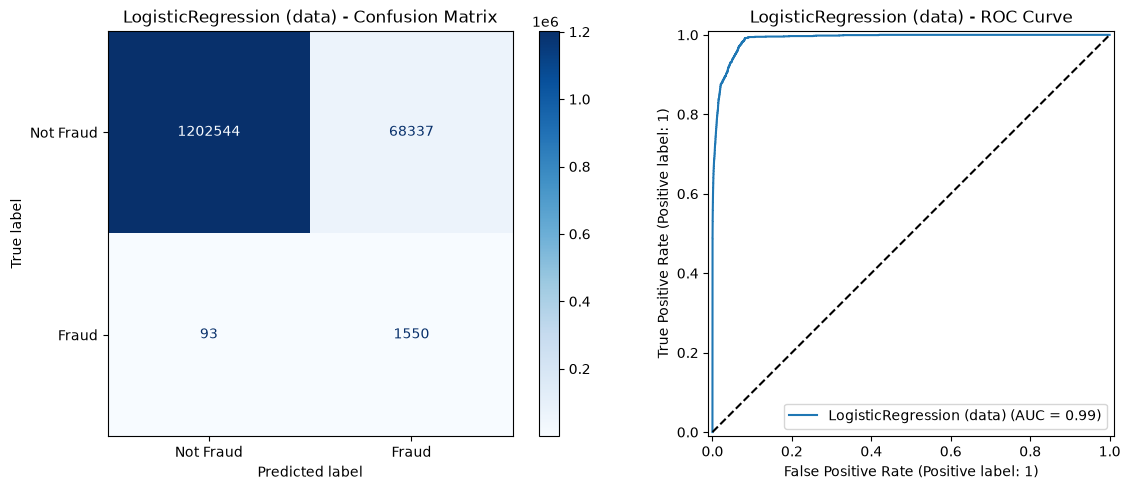


===== XGBoost (data) =====
              precision    recall  f1-score   support

           0     1.0000    0.9986    0.9993   1270881
           1     0.4811    0.9921    0.6480      1643

    accuracy                         0.9986   1272524
   macro avg     0.7405    0.9954    0.8236   1272524
weighted avg     0.9993    0.9986    0.9988   1272524



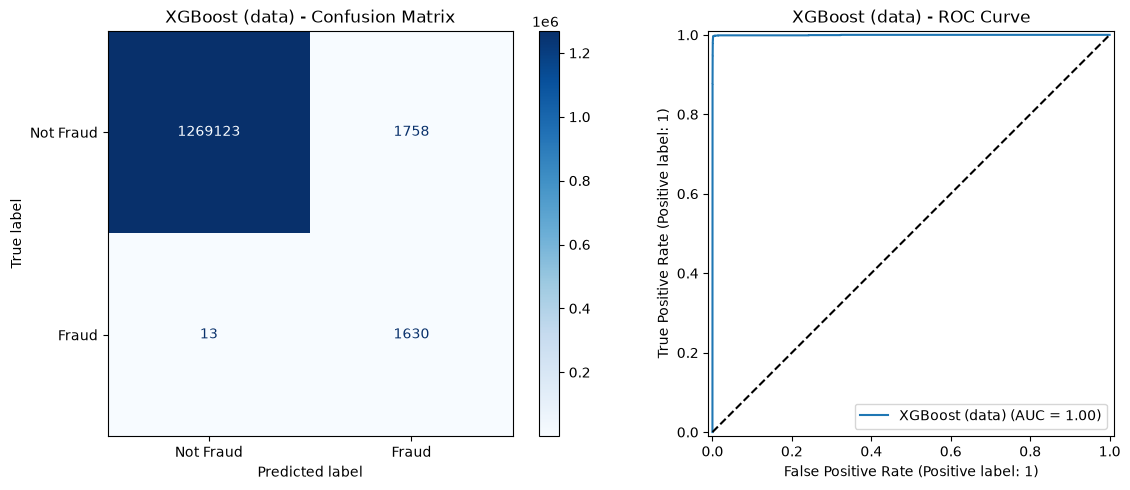

({'LogisticRegression': Pipeline(steps=[('scaler', StandardScaler()),
                  ('model',
                   LogisticRegression(class_weight='balanced', max_iter=1000,
                                      n_jobs=-1))]),
  'XGBoost': Pipeline(steps=[('scaler', StandardScaler()),
                  ('model',
                   XGBClassifier(base_score=None, booster=None, callbacks=None,
                                 colsample_bylevel=None, colsample_bynode=None,
                                 colsample_bytree=None, device=None,
                                 early_stopping_rounds=None,
                                 enable_categorical=True, eval_metric='aucpr',
                                 feature_types=None, feature_weights=None,
                                 gamma=None, grow_policy=None,
                                 importance_type=None,
                                 interaction_constraints=None, learning_rate=0.1,
                                 max_bin

In [24]:
run_pipeline(data, dataset_name="data")

/media/yillzahar/863270C13270B82F/Real-Time-Transaction-Fraud-Detection/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)



===== LogisticRegression (data_log) =====
              precision    recall  f1-score   support

           0     1.0000    0.9517    0.9752   1270881
           1     0.0258    0.9903    0.0503      1643

    accuracy                         0.9517   1272524
   macro avg     0.5129    0.9710    0.5128   1272524
weighted avg     0.9987    0.9517    0.9741   1272524



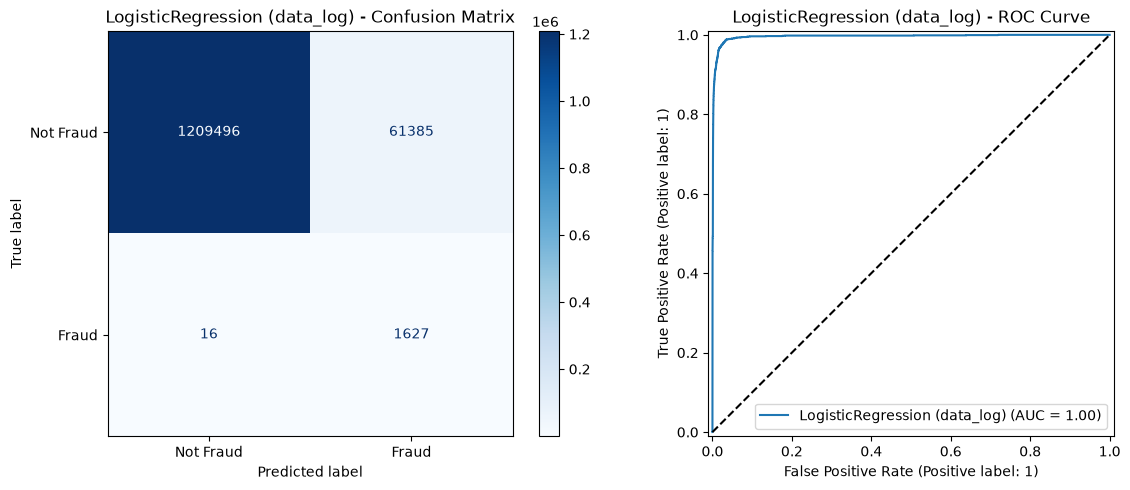


===== XGBoost (data_log) =====
              precision    recall  f1-score   support

           0     1.0000    0.9986    0.9993   1270881
           1     0.4749    0.9915    0.6422      1643

    accuracy                         0.9986   1272524
   macro avg     0.7375    0.9950    0.8208   1272524
weighted avg     0.9993    0.9986    0.9988   1272524



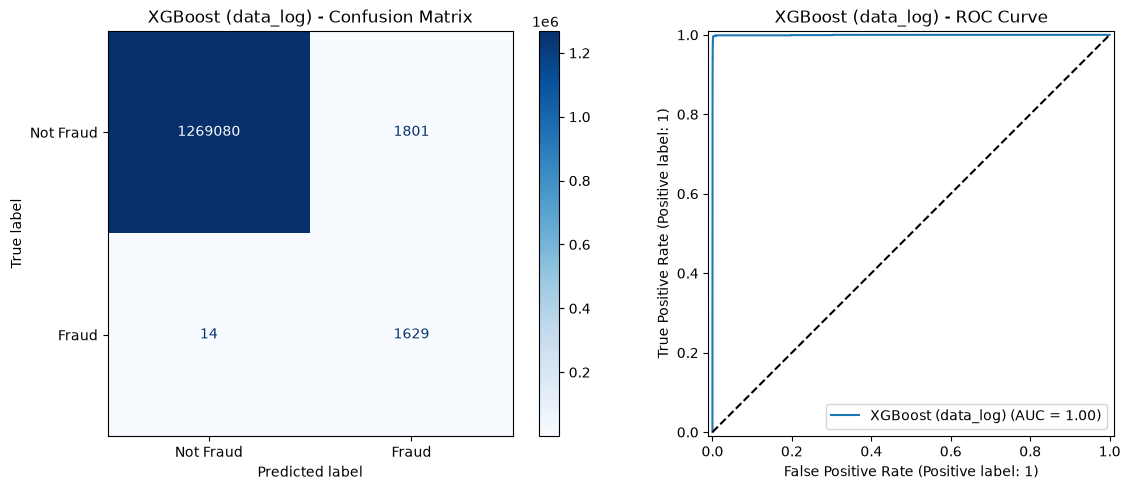

({'LogisticRegression': Pipeline(steps=[('scaler', StandardScaler()),
                  ('model',
                   LogisticRegression(class_weight='balanced', max_iter=1000,
                                      n_jobs=-1))]),
  'XGBoost': Pipeline(steps=[('scaler', StandardScaler()),
                  ('model',
                   XGBClassifier(base_score=None, booster=None, callbacks=None,
                                 colsample_bylevel=None, colsample_bynode=None,
                                 colsample_bytree=None, device=None,
                                 early_stopping_rounds=None,
                                 enable_categorical=True, eval_metric='aucpr',
                                 feature_types=None, feature_weights=None,
                                 gamma=None, grow_policy=None,
                                 importance_type=None,
                                 interaction_constraints=None, learning_rate=0.1,
                                 max_bin

In [25]:
run_pipeline(data_log, dataset_name="data_log")

/media/yillzahar/863270C13270B82F/Real-Time-Transaction-Fraud-Detection/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)



===== LogisticRegression (data) =====
              precision    recall  f1-score   support

           0     0.9999    0.9462    0.9723   1270881
           1     0.0222    0.9434    0.0433      1643

    accuracy                         0.9462   1272524
   macro avg     0.5111    0.9448    0.5078   1272524
weighted avg     0.9987    0.9462    0.9711   1272524



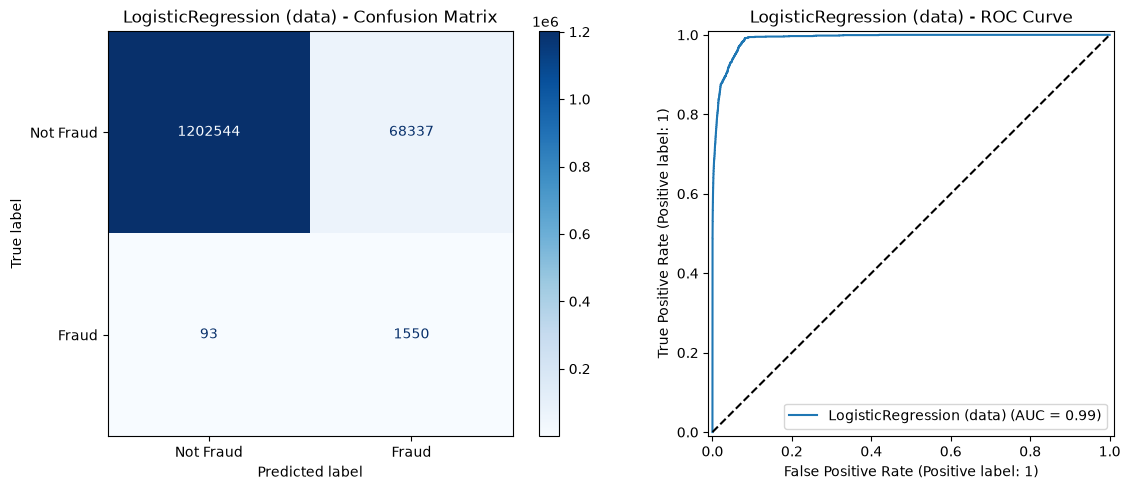


===== XGBoost (data) =====
              precision    recall  f1-score   support

           0     1.0000    0.9986    0.9993   1270881
           1     0.4811    0.9921    0.6480      1643

    accuracy                         0.9986   1272524
   macro avg     0.7405    0.9954    0.8236   1272524
weighted avg     0.9993    0.9986    0.9988   1272524



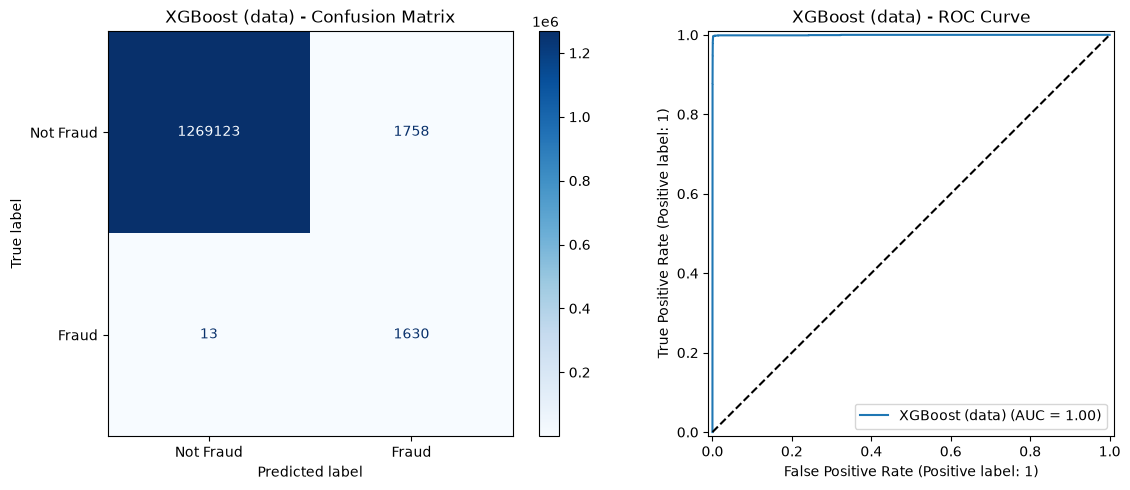

threshold=0.995  precision=0.9013  recall=0.8223  f1=0.8600

===== XGBoost (data, tuned) =====
              precision    recall  f1-score   support

           0     0.9998    0.9999    0.9998   1270881
           1     0.9013    0.8223    0.8600      1643

    accuracy                         0.9997   1272524
   macro avg     0.9505    0.9111    0.9299   1272524
weighted avg     0.9996    0.9997    0.9996   1272524



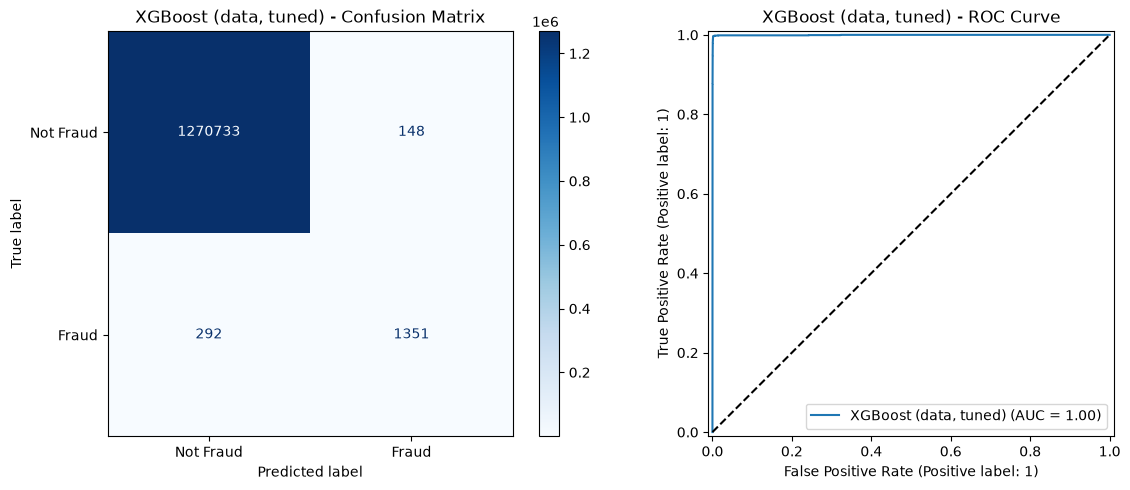

{'model': 'XGBoost (data, tuned)',
 'roc_auc': 0.9995523834915421,
 'pr_auc': 0.9464083659433821}

In [26]:
from sklearn.metrics import precision_recall_curve

def find_best_threshold(model, X_test, y_test):
    """Threshold that maximizes F1 for the fraud class."""
    y_proba = model.predict_proba(X_test)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_test, y_proba)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    best = np.argmax(f1[:-1])
    print(f"threshold={thresholds[best]:.3f}  precision={precision[best]:.4f}  "
          f"recall={recall[best]:.4f}  f1={f1[best]:.4f}")
    return thresholds[best]

# run_pipeline returns (models, results), so keep them:
models_raw, res_raw = run_pipeline(data, "data")

X, y = prepare_features(data)
X_train, X_test, y_train, y_test = split_data(X, y)   # same random_state → same split

best_t = find_best_threshold(models_raw["XGBoost"], X_test, y_test)
evaluate_model("XGBoost (data, tuned)", models_raw["XGBoost"], X_test, y_test, threshold=best_t)



===== XGBoost (with post-tx balances) =====
train steps   1-280 | rows 3,792,821 | fraud rate 0.0837%
val   steps 281-354 | rows 1,276,276 | fraud rate 0.0611%
test  steps 355-743 | rows 1,293,523 | fraud rate 0.3292%
Best threshold on validation: 0.36 (cost=3,143)


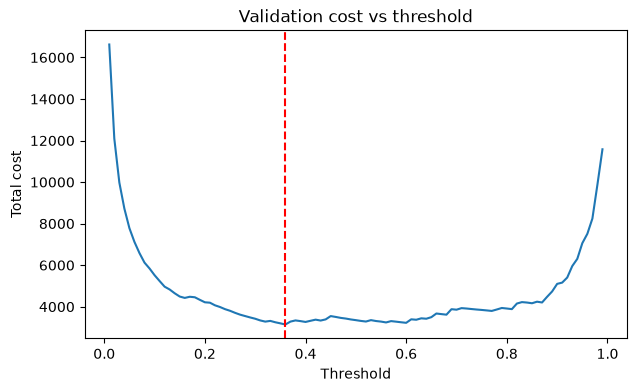

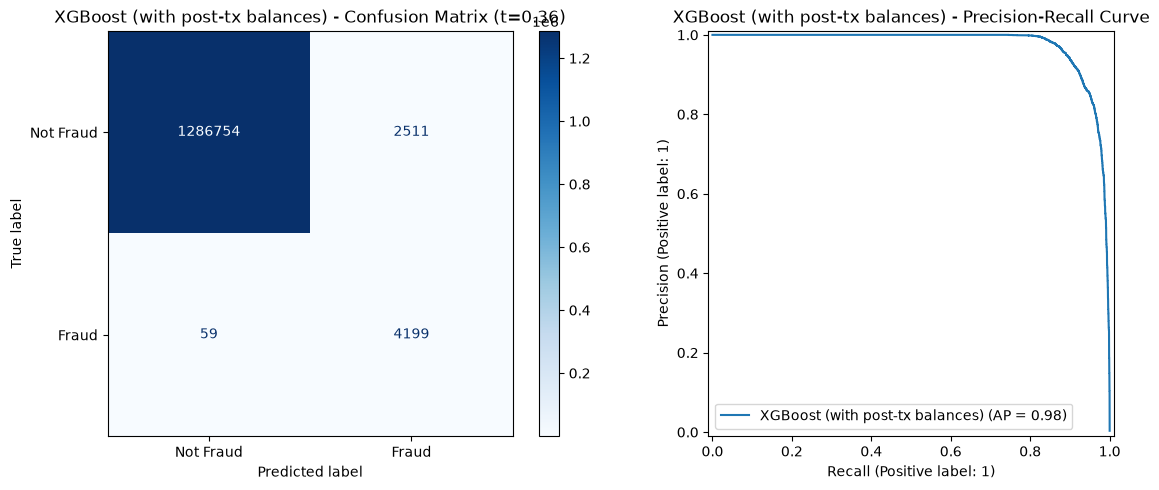


===== XGBoost (pre-tx only) =====
train steps   1-280 | rows 3,792,821 | fraud rate 0.0837%
val   steps 281-354 | rows 1,276,276 | fraud rate 0.0611%
test  steps 355-743 | rows 1,293,523 | fraud rate 0.3292%
Best threshold on validation: 0.67 (cost=6,584)


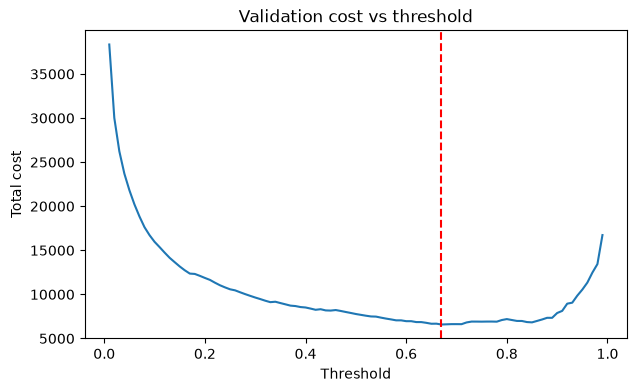

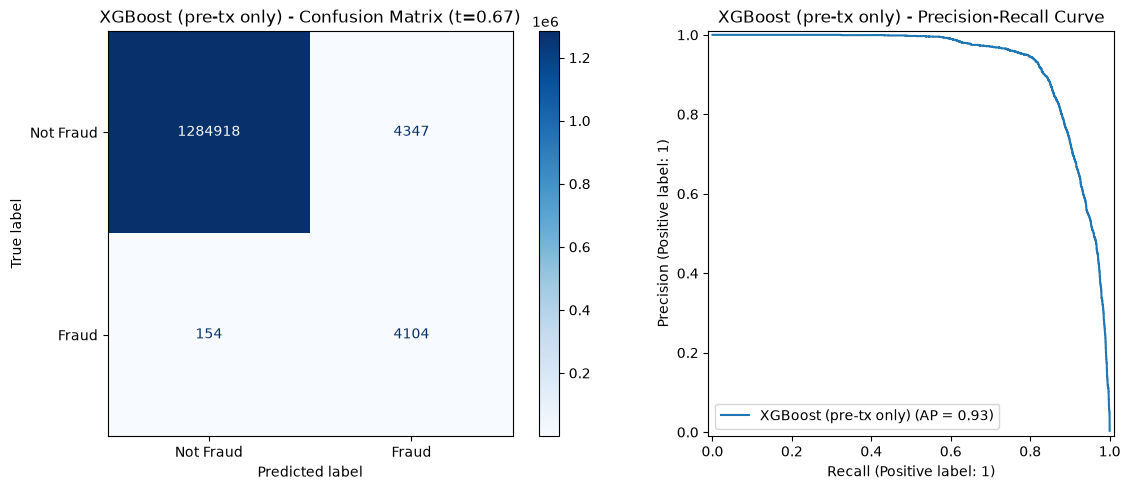


===== XGBoost log (pre-tx only) =====
train steps   1-280 | rows 3,792,821 | fraud rate 0.0837%
val   steps 281-354 | rows 1,276,276 | fraud rate 0.0611%
test  steps 355-743 | rows 1,293,523 | fraud rate 0.3292%
Best threshold on validation: 0.79 (cost=6,596)


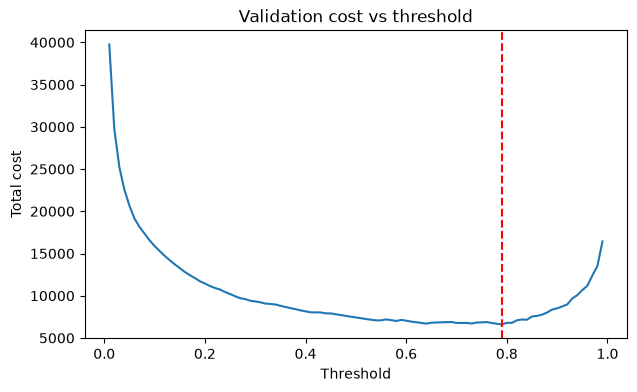

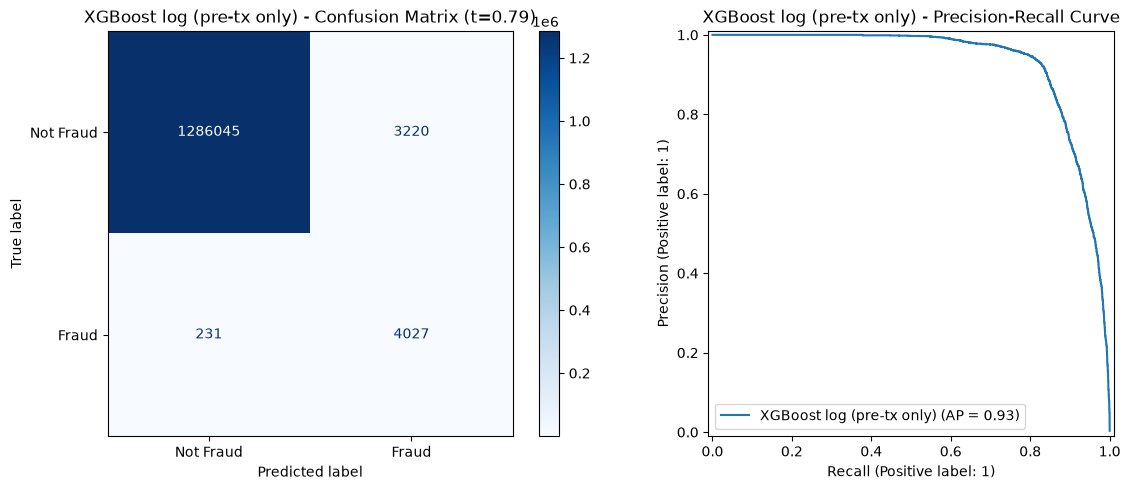

,threshold,precision,recall,pr_auc,fpr,TP,FP,FN,TN
model,,,,,,,,,
XGBoost (with post-tx balances),0.36,0.6258,0.9861,0.9763,0.0019,4199,2511,59,1286754
XGBoost (pre-tx only),0.67,0.4856,0.9638,0.9292,0.0034,4104,4347,154,1284918
XGBoost log (pre-tx only),0.79,0.5557,0.9457,0.9312,0.0025,4027,3220,231,1286045


In [ ]:
PRE_TX_COLS  = ["amount", "oldbalanceOrg", "oldbalanceDest"]                  # known before the transaction
ALL_COLS     = PRE_TX_COLS + ["newbalanceOrig", "newbalanceDest"]              # includes post-transaction values

_, m_all  = run_experiment(data, ALL_COLS,    "XGBoost (with post-tx balances)")
_, m_pre  = run_experiment(data, PRE_TX_COLS, "XGBoost (pre-tx only)")
_, m_prel = run_experiment(data_log, [c + "_log" for c in PRE_TX_COLS], "XGBoost log (pre-tx only)")

pd.DataFrame([m_all, m_pre, m_prel]).set_index("model").round(4)


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, precision_score,
                             recall_score, average_precision_score, PrecisionRecallDisplay)

NUM_COLS = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]


# 1. Chronological split ------------------------------------------------------
def chronological_split(df, train_frac=0.6, val_frac=0.2, time_col="step"):
    """Split by time: earliest steps -> train, next -> val, latest -> test.
    Cut points fall between steps, so no step is shared across periods."""
    step_counts = df[time_col].value_counts().sort_index()
    cum = step_counts.cumsum() / len(df)
    train_end = cum[cum <= train_frac].index.max()
    val_end = cum[cum <= train_frac + val_frac].index.max()

    train = df[df[time_col] <= train_end]
    val = df[(df[time_col] > train_end) & (df[time_col] <= val_end)]
    test = df[df[time_col] > val_end]

    for name, part in [("train", train), ("val", val), ("test", test)]:
        print(f"{name:5s} steps {part[time_col].min():>3}-{part[time_col].max():>3} | "
              f"rows {len(part):>9,} | fraud rate {part['isFraud'].mean():.4%}")
    return train, val, test


def prepare_features(df, num_cols, target="isFraud"):
    """Numeric cols + one-hot 'type' + hour of day. Drops IDs, step, isFlaggedFraud."""
    X = df[num_cols].copy()
    X["hour"] = df["step"] % 24
    X = pd.concat([X, pd.get_dummies(df["type"], prefix="type", dtype=int)], axis=1)
    return X, df[target]


# 2. Train XGBoost on the training period --------------------------------------
def train_xgb(X_train, y_train):
    neg, pos = np.bincount(y_train)
    model = XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.1,
        scale_pos_weight=neg / pos,
        tree_method="hist", eval_metric="aucpr",
        n_jobs=-1, random_state=42)
    model.fit(X_train, y_train)
    return model


# 3. Choose threshold on validation using a business cost ---------------------
def choose_threshold(y_true, y_proba, cost_fn=100, cost_fp=1):
    """Pick the threshold that minimizes total cost = FN*cost_fn + FP*cost_fp.
    cost_fn: cost of a missed fraud; cost_fp: cost of reviewing a false alert."""
    thresholds = np.linspace(0.01, 0.99, 99)
    costs = []
    for t in thresholds:
        y_pred = (y_proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
        costs.append(fn * cost_fn + fp * cost_fp)
    best = int(np.argmin(costs))
    print(f"Best threshold on validation: {thresholds[best]:.2f} (cost={costs[best]:,.0f})")

    plt.figure(figsize=(7, 4))
    plt.plot(thresholds, costs)
    plt.axvline(thresholds[best], color="red", linestyle="--")
    plt.xlabel("Threshold"); plt.ylabel("Total cost"); plt.title("Validation cost vs threshold")
    plt.show()
    return thresholds[best]


# 4 + 6. Evaluate the fixed threshold on test ---------------------------------
def evaluate_at_threshold(name, y_true, y_proba, threshold):
    y_pred = (y_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    metrics = {
        "model": name,
        "threshold": threshold,
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "pr_auc": average_precision_score(y_true, y_proba),
        "fpr": fp / (fp + tn),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=[0, 1]),
                           display_labels=["Not Fraud", "Fraud"]).plot(
        ax=axes[0], cmap="Blues", values_format="d")
    axes[0].set_title(f"{name} - Confusion Matrix (t={threshold:.2f})")
    PrecisionRecallDisplay.from_predictions(y_true, y_proba, ax=axes[1], name=name)
    axes[1].set_title(f"{name} - Precision-Recall Curve")
    plt.tight_layout(); plt.show()
    return metrics


# Full experiment for one data version ----------------------------------------
def run_experiment(df, num_cols, name, cost_fn=100, cost_fp=1, train_frac=0.6, val_frac=0.2):
    print(f"\n===== {name} =====")
    train, val, test = chronological_split(df, train_frac, val_frac)
    X_train, y_train = prepare_features(train, num_cols)
    X_val, y_val = prepare_features(val, num_cols)
    X_test, y_test = prepare_features(test, num_cols)
    X_val = X_val.reindex(columns=X_train.columns, fill_value=0)    # keep same type_* columns
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

    model = train_xgb(X_train, y_train)
    threshold = choose_threshold(y_val, model.predict_proba(X_val)[:, 1], cost_fn, cost_fp)
    metrics = evaluate_at_threshold(name, y_test, model.predict_proba(X_test)[:, 1], threshold)
    return model, metrics



===== data =====
train steps   1-280 | rows 3,792,821 | fraud rate 0.0837%
val   steps 281-354 | rows 1,276,276 | fraud rate 0.0611%
test  steps 355-743 | rows 1,293,523 | fraud rate 0.3292%
Best threshold on validation: 0.36 (cost=3,143)


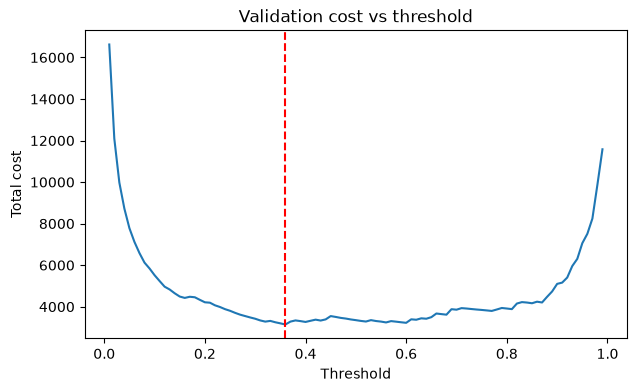

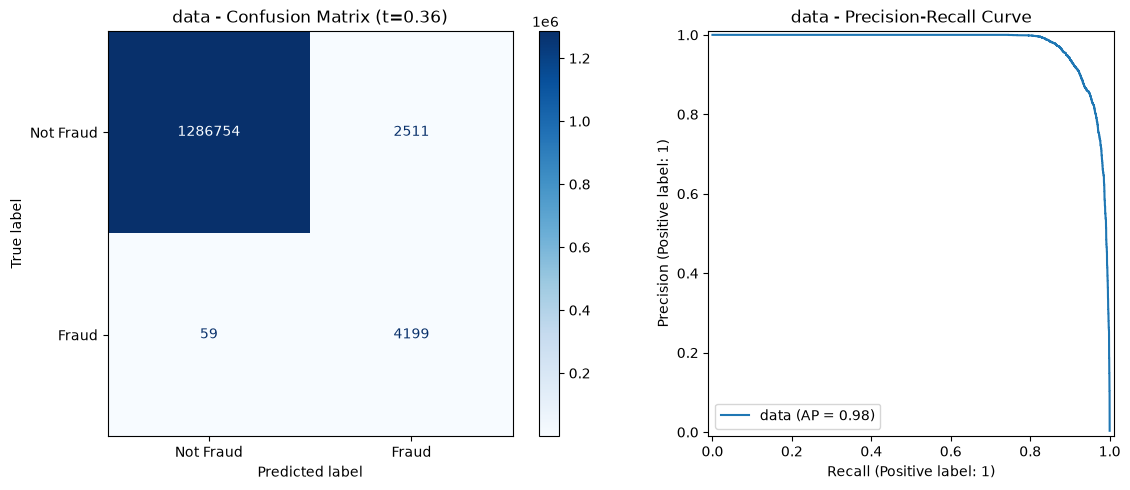

(XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=None, device=None, early_stopping_rounds=None,
               enable_categorical=True, eval_metric='aucpr', feature_types=None,
               feature_weights=None, gamma=None, grow_policy=None,
               importance_type=None, interaction_constraints=None,
               learning_rate=0.1, max_bin=None, max_cat_threshold=None,
               max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
               max_leaves=None, min_child_weight=None, missing=nan,
               monotone_constraints=None, multi_strategy=None, n_estimators=300,
               n_jobs=-1, num_parallel_tree=None, ...),
 {'model': 'data',
  'threshold': np.float64(0.36000000000000004),
  'precision': 0.6257824143070044,
  'recall': 0.9861437294504463,
  'pr_auc': 0.9762905977888895,
  'fpr': np.float64(0.0019476213191236868),
  'TP': np.int64(4199)

In [28]:
run_experiment(data, NUM_COLS, "data", cost_fn=100, cost_fp=1)

# Feature engineering (pre-transaction only)

**Goal:** improve the leakage-free model (E2) using only information available *before* the transaction executes.

**Not used as inputs:** `isFraud`, `isFlaggedFraud`, `newbalanceOrig`, `newbalanceDest`, `nameOrig`/`nameDest` IDs, and any customer history (no feature store exists yet).

| Feature | Definition | Business rationale | Available at inference? |
|---|---|---|---|
| `amt_to_orig_bal` | amount / oldbalanceOrg (NaN if balance is 0) | Share of the sender's funds being moved | Yes: request amount + current sender balance |
| `drains_orig` | \|amount − oldbalanceOrg\| < 0.01 and balance > 0 | Account takeover usually empties the account | Yes |
| `exceeds_orig_bal` | amount > oldbalanceOrg | Spending beyond available funds is a different pattern from fraud | Yes |
| `orig_bal_zero` | oldbalanceOrg == 0 | Empty / unfunded sender | Yes |
| `dest_bal_zero` | oldbalanceDest == 0 | New or mule receiving account | Yes, for on-platform receivers (same as `oldbalanceDest`) |
| `amt_to_dest_bal` | amount / oldbalanceDest (NaN if 0) | Inflow size relative to receiver balance | Same as above |
| `is_max_amount` | amount >= 10,000,000 | Transfers at the system limit (fraud is split into max-size chunks) | Yes: limit is a config value |
| `amt_vs_type_median` | amount / median amount of its `type` (**median fitted on train only**) | Unusually large for this transaction type | Yes: stored constant per type |
| kept | `amount`, `oldbalanceOrg`, `oldbalanceDest`, `hour`, `type_*` | baseline | Yes |

**Training-period evidence (TRANSFER / CASH_OUT):** amount ≈ sender balance in 97.9% of fraud vs 0.0% of non-fraud; amount > balance in 0.9% of fraud vs 90.0% of non-fraud.

**Business cost function:** `cost = 100 × FN + 1 × FP`, so one missed fraud costs as much as reviewing 100 false alerts. The threshold is chosen on the **validation** period with this cost, then applied unchanged to the **test** period.

**Protocol:** identical chronological splits for every experiment (train steps 1–280, val 281–354, test 355–743), same XGBoost hyperparameters (`train_xgb`).

In [ ]:
# Split once so every experiment uses identical chronological periods
train, val, test = chronological_split(data)
splits_raw = (train, val, test)
splits_log = tuple(data_log.loc[part.index] for part in splits_raw)

# Business cost function: one missed fraud costs as much as reviewing 100 false alerts
COST_FN, COST_FP = 100, 1

In [ ]:
MAX_AMOUNT = 10_000_000  # per-transaction limit in PaySim


def safe_ratio(num, den):
    """num / den, NaN where den <= 0 (XGBoost handles NaN natively)."""
    num, den = np.asarray(num, dtype=float), np.asarray(den, dtype=float)
    return np.where(den > 0, num / np.where(den > 0, den, 1), np.nan)


def fit_feature_stats(train_df):
    """Learned preprocessing - fitted on the training period only."""
    return {"type_median_amount": train_df.groupby("type")["amount"].median().to_dict()}


def build_engineered_features(df, stats):
    """Stateless features computable from the incoming transaction alone."""
    X = df[["amount", "oldbalanceOrg", "oldbalanceDest"]].copy()
    X["amt_to_orig_bal"] = safe_ratio(df["amount"], df["oldbalanceOrg"])
    X["drains_orig"] = ((df["amount"] - df["oldbalanceOrg"]).abs() < 0.01) & (df["oldbalanceOrg"] > 0)
    X["exceeds_orig_bal"] = df["amount"] > df["oldbalanceOrg"]
    X["orig_bal_zero"] = df["oldbalanceOrg"] == 0
    X["dest_bal_zero"] = df["oldbalanceDest"] == 0
    X["amt_to_dest_bal"] = safe_ratio(df["amount"], df["oldbalanceDest"])
    X["is_max_amount"] = df["amount"] >= MAX_AMOUNT
    type_median = df["type"].map(stats["type_median_amount"])
    X["amt_vs_type_median"] = safe_ratio(df["amount"], type_median)
    X["hour"] = df["step"] % 24
    X = pd.concat([X, pd.get_dummies(df["type"], prefix="type", dtype=int)], axis=1)
    bool_cols = X.select_dtypes(bool).columns
    X[bool_cols] = X[bool_cols].astype(int)
    return X


def prepare_engineered(df, stats, target="isFraud"):
    return build_engineered_features(df, stats), df[target]

In [ ]:
# Same as before, plus business cost columns
def evaluate_at_threshold(name, y_true, y_proba, threshold, cost_fn=COST_FN, cost_fp=COST_FP):
    y_pred = (y_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    metrics = {
        "model": name,
        "threshold": threshold,
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "pr_auc": average_precision_score(y_true, y_proba),
        "fpr": fp / (fp + tn),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "cost": fn * cost_fn + fp * cost_fp,
        "cost_per_fraud": (fn * cost_fn + fp * cost_fp) / (tp + fn),
    }

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=[0, 1]),
                           display_labels=["Not Fraud", "Fraud"]).plot(
        ax=axes[0], cmap="Blues", values_format="d")
    axes[0].set_title(f"{name} - Confusion Matrix (t={threshold:.2f})")
    PrecisionRecallDisplay.from_predictions(y_true, y_proba, ax=axes[1], name=name)
    axes[1].set_title(f"{name} - Precision-Recall Curve")
    plt.tight_layout(); plt.show()
    return metrics


def run_on_splits(name, make_X, splits, cost_fn=COST_FN, cost_fp=COST_FP):
    """Train on train, pick threshold on val, evaluate once on test.
    make_X(df) -> (X, y); any learned stats must already be fitted on train."""
    print(f"\n===== {name} =====")
    train_df, val_df, test_df = splits
    X_train, y_train = make_X(train_df)
    X_val, y_val = make_X(val_df)
    X_test, y_test = make_X(test_df)
    X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

    model = train_xgb(X_train, y_train)
    threshold = choose_threshold(y_val, model.predict_proba(X_val)[:, 1], cost_fn, cost_fp)
    metrics = evaluate_at_threshold(name, y_test, model.predict_proba(X_test)[:, 1],
                                    threshold, cost_fn, cost_fp)
    return model, metrics

In [ ]:
PRE_TX_COLS = ["amount", "oldbalanceOrg", "oldbalanceDest"]
POST_TX_COLS = PRE_TX_COLS + ["newbalanceOrig", "newbalanceDest"]
LOG_PRE_TX_COLS = [c + "_log" for c in PRE_TX_COLS]

feature_stats = fit_feature_stats(splits_raw[0])  # train period only

_, e1 = run_on_splits("E1 post-tx (leaky, reference)", lambda d: prepare_features(d, POST_TX_COLS), splits_raw)
_, e2 = run_on_splits("E2 pre-tx baseline", lambda d: prepare_features(d, PRE_TX_COLS), splits_raw)
_, e3 = run_on_splits("E3 pre-tx log", lambda d: prepare_features(d, LOG_PRE_TX_COLS), splits_log)
model_e4, e4 = run_on_splits("E4 pre-tx engineered", lambda d: prepare_engineered(d, feature_stats), splits_raw)

comparison = pd.DataFrame([e1, e2, e3, e4]).set_index("model")
comparison.round(4)

In [ ]:
# Ablation: how much depends on the "drains the account" rule?
ABLATE = ["drains_orig", "amt_to_orig_bal"]  # amt_to_orig_bal == 1.0 encodes the same rule
_, e5 = run_on_splits("E5 engineered w/o drain signal",
                      lambda d: (lambda X, y: (X.drop(columns=ABLATE), y))(*prepare_engineered(d, feature_stats)),
                      splits_raw)

comparison = pd.DataFrame([e1, e2, e3, e4, e5]).set_index("model")
comparison.round(4)

In [ ]:
importance = pd.Series(model_e4.get_booster().get_score(importance_type="gain")).sort_values()
importance.plot.barh(figsize=(8, 6), title="E4 feature importance (gain)")
plt.tight_layout(); plt.show()
importance.sort_values(ascending=False).round(1)

## Results (chronological test period, steps 355–743)

| Experiment | Threshold | Precision | Recall | PR-AUC | FPR | FP | FN | Cost |
|---|---|---|---|---|---|---|---|---|
| E1 post-tx (leaky, reference) | 0.36 | 0.626 | 0.986 | 0.976 | 0.0019 | 2,511 | 59 | 8,411 |
| E2 pre-tx baseline | 0.67 | 0.486 | 0.964 | 0.929 | 0.0034 | 4,347 | 154 | 19,747 |
| E3 pre-tx log | 0.79 | 0.556 | 0.946 | 0.931 | 0.0025 | 3,220 | 231 | 26,320 |
| **E4 pre-tx engineered** | 0.97 | **0.9995** | **0.998** | **0.9998** | **0.0000** | **2** | **10** | **1,002** |
| E5 engineered w/o drain signal | 0.53 | 0.701 | 0.981 | 0.971 | 0.0014 | 1,780 | 79 | 9,680 |

## Analysis

- **Feature engineering helped, a lot.** E4 cuts test cost from 19,747 (E2) to 1,002, about 95% lower. It also beats the leaky post-transaction model E1 without using any post-transaction data.
- **Most of the gain comes from one rule.** `drains_orig` dominates the gain importance, and the validation cost hit 0. In PaySim, the fraud agent always moves the sender's entire balance. That is a rule of the simulator, so E4's near-perfect score is an **upper bound**, not a production estimate. It is not target leakage (both inputs are known before the transaction), but real fraudsters do not always empty accounts.
- **The improvement is robust without that rule.** E5 removes `drains_orig` and `amt_to_orig_bal`, and still halves the baseline cost (9,680 vs 19,747), with PR-AUC 0.971 vs 0.929. The other features (`is_max_amount`, `exceeds_orig_bal`, `amt_to_dest_bal`, type/balance flags) carry real signal.
- **Log transform (E3) is not a real improvement.** Trees are invariant to monotonic transforms. The difference from E2 is binning/threshold noise, and its cost is actually higher.
- **Drift warning:** the test fraud rate (0.33%) is about 4× the training rate (0.08%). That makes test precision look better than it would at the training-period base rate.

## Recommendation

1. **Adopt E4's feature set** as the new pre-transaction model, and report **E5 as the conservative estimate** of real-world performance.
2. **Next step toward production:** move `build_engineered_features` and the stored `feature_stats` (type medians) into one shared function in `src/`, so training and serving compute identical features. Then add a check that scores a sample with both paths and compares.
3. Re-select the threshold periodically on recent data and monitor the fraud base rate, since precision depends on it.
4. Only after that, consider history/velocity features, which need a feature store.